In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

STUDENT_NUMBER = "2024109040"  # CHANGE: replace with your student number, in quotes
assert STUDENT_NUMBER != "CHANGE_ME" and STUDENT_NUMBER[-1].isdigit()

digit = int(STUDENT_NUMBER[-1])
K_BY_DIGIT = {0: 50, 1: 50, 2: 50, 3: 100, 4: 100, 5: 100, 6: 200, 7: 200, 8: 500, 9: 500}
C_BY_DIGIT = {0: 0.1, 1: 0.1, 2: 0.1, 3: 0.3, 4: 0.3, 5: 0.3, 6: 1.0, 7: 1.0, 8: 3.0, 9: 3.0}
K_FEATURES, C_VALUE = K_BY_DIGIT[digit], C_BY_DIGIT[digit]

PROJECT = Path("/workspace")
DATA = PROJECT / "data"
RESULTS = PROJECT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print(f"digit={digit}; k={K_FEATURES}; C={C_VALUE}")

digit=0; k=50; C=0.1


In [2]:
expression = pd.read_csv(DATA / "luad_expression.csv.gz")
metadata = pd.read_csv(DATA / "luad_metadata.csv")
genes = pd.read_csv(DATA / "gene_annotation.csv")

assert expression.shape[0] == metadata.shape[0] == 100
assert set(metadata["label"]) == {"Normal", "Tumor"}
assert not metadata["patient_id"].duplicated().any()
assert set(expression["sample_id"]) == set(metadata["sample_id"])

data = metadata.merge(expression, on="sample_id", validate="one_to_one")
feature_columns = expression.columns.drop("sample_id")
X = data[feature_columns]
y = data["label"]

print(X.shape)
print(y.value_counts())
print(pd.crosstab(data["tissue_source_site"], y))

(100, 60660)
label
Normal    50
Tumor     50
Name: count, dtype: int64
label               Normal  Tumor
tissue_source_site               
5                        0     35
35                       0      4
38                       4      7
44                      17      4
49                       7      0
50                       8      0
55                      14      0


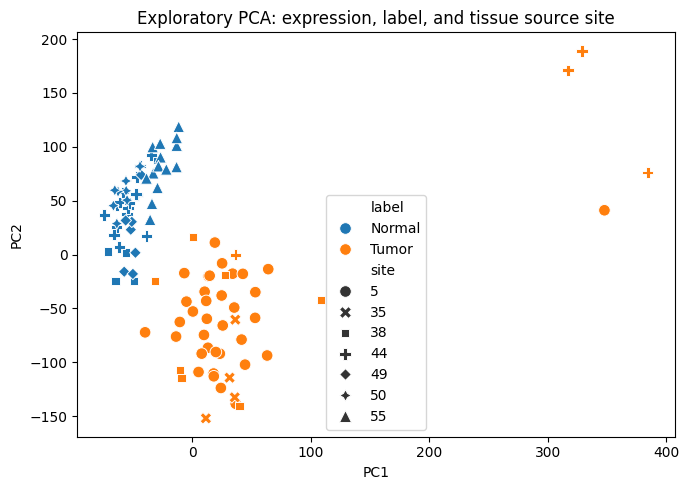

In [3]:
nonconstant = VarianceThreshold().fit_transform(X)
coords = PCA(n_components=2, random_state=131).fit_transform(StandardScaler().fit_transform(nonconstant))
pca_plot = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "label": y, "site": data["tissue_source_site"]})

plt.figure(figsize=(7, 5))
sns.scatterplot(data=pca_plot, x="PC1", y="PC2", hue="label", style="site", s=70)
plt.title("Exploratory PCA: expression, label, and tissue source site")
plt.tight_layout()
plt.savefig(FIGURES / "pca_label_site.png", dpi=180)
plt.show()

In [4]:
RANDOM_SEED = 131  # Do not change after this cell runs.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED
)
assert len(X_test) == 20 and y_test.value_counts().to_dict() == {"Normal": 10, "Tumor": 10}
print(X_dev.shape, X_test.shape)

(80, 60660) (20, 60660)


In [5]:
leaky_X = VarianceThreshold().fit_transform(X_dev)
leaky_X = SelectKBest(f_classif, k=K_FEATURES).fit_transform(leaky_X, y_dev)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
leaky_scores = cross_validate(
    LogisticRegression(C=C_VALUE, class_weight="balanced", max_iter=3000),
    leaky_X, y_dev, cv=cv,
    scoring={"balanced_accuracy": "balanced_accuracy", "roc_auc": "roc_auc"},
)
print("LEAKY mean balanced accuracy:", leaky_scores["test_balanced_accuracy"].mean())
print("LEAKY mean ROC-AUC:", leaky_scores["test_roc_auc"].mean())

LEAKY mean balanced accuracy: 1.0
LEAKY mean ROC-AUC: 1.0


In [14]:

pipeline.fit(X_dev, y_dev)

test_probability = pipeline.predict_proba(X_test)[
    :, list(pipeline.classes_).index("Tumor")
]
test_prediction = pipeline.predict(X_test)

test_metrics = pd.DataFrame([{
    "balanced_accuracy": balanced_accuracy_score(
        y_test, test_prediction
    ),
    "roc_auc": roc_auc_score(
        (y_test == "Tumor").astype(int),
        test_probability
    ),
    "n_test": len(y_test),
}])

test_metrics.to_csv(
    RESULTS / "internal_holdout_metrics.csv",
    index=False
)

test_metrics


,balanced_accuracy,roc_auc,n_test
0,1.0,1.0,20


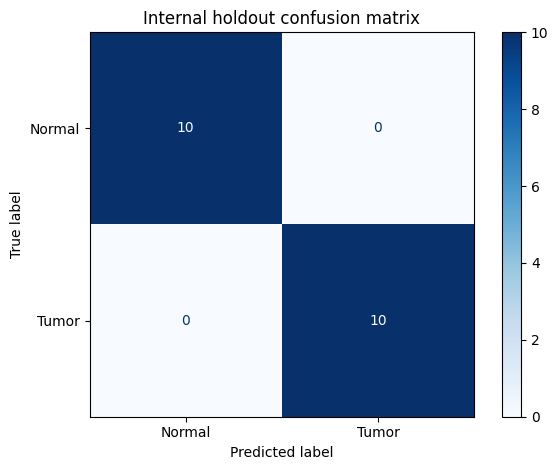

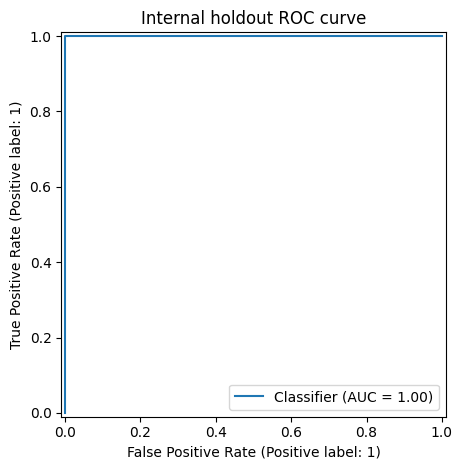

,sample_id,tissue_source_site,label,tumor_probability,prediction
31,TCGA-50-5933-11A,50,Normal,0.011291,Normal
42,TCGA-55-6978-11A,55,Normal,0.004942,Normal
94,TCGA-38-7271-01A,38,Tumor,0.896070,Tumor
12,TCGA-44-5645-11A,44,Normal,0.002184,Normal
43,TCGA-55-6979-11A,55,Normal,0.066829,Normal
29,TCGA-50-5931-11A,50,Normal,0.003295,Normal
56,TCGA-05-4389-01A,5,Tumor,0.995238,Tumor
81,TCGA-05-5425-01A,5,Tumor,0.978663,Tumor
32,TCGA-50-5935-11A,50,Normal,0.009593,Normal
65,TCGA-05-4410-01A,5,Tumor,0.993286,Tumor


In [15]:
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, cmap="Blues")
plt.title("Internal holdout confusion matrix")
plt.tight_layout()
plt.savefig(FIGURES / "internal_holdout_confusion_matrix.png", dpi=180)
plt.show()

RocCurveDisplay.from_predictions((y_test == "Tumor").astype(int), test_probability)
plt.title("Internal holdout ROC curve")
plt.tight_layout()
plt.savefig(FIGURES / "internal_holdout_roc.png", dpi=180)
plt.show()

predictions = data.loc[X_test.index, ["sample_id", "tissue_source_site", "label"]].copy()
predictions["tumor_probability"] = test_probability
predictions["prediction"] = test_prediction
predictions.to_csv(RESULTS / "internal_holdout_predictions.csv", index=False)
predictions

In [16]:
nonconstant_names = feature_columns[pipeline.named_steps["nonconstant"].get_support()]
selected_names = nonconstant_names[pipeline.named_steps["features"].get_support()]
coefficients = pd.DataFrame({
    "gene_id": selected_names,
    "coefficient": pipeline.named_steps["model"].coef_.ravel(),
})
coefficients = coefficients.merge(genes, on="gene_id", how="left")
coefficients["absolute_coefficient"] = coefficients["coefficient"].abs()
coefficients.sort_values("absolute_coefficient", ascending=False).to_csv(
    RESULTS / "selected_feature_coefficients.csv", index=False
)
coefficients.sort_values("absolute_coefficient", ascending=False).head(10)

,gene_id,coefficient,gene_name,gene_type,absolute_coefficient
5,ENSG00000102104.9,-0.149594,RS1,protein_coding,0.149594
14,ENSG00000135604.10,-0.135744,STX11,protein_coding,0.135744
4,ENSG00000096063.16,0.129317,SRPK1,protein_coding,0.129317
48,ENSG00000261863.1,-0.127767,LINC01996,lncRNA,0.127767
42,ENSG00000234281.5,-0.127280,LANCL1-AS1,lncRNA,0.127280
29,ENSG00000168481.9,-0.121755,LGI3,protein_coding,0.121755
18,ENSG00000140600.17,-0.120283,SH3GL3,protein_coding,0.120283
49,ENSG00000272379.1,-0.115757,AL008729.2,lncRNA,0.115757
22,ENSG00000157654.19,-0.114127,PALM2AKAP2,protein_coding,0.114127
33,ENSG00000170323.9,-0.113218,FABP4,protein_coding,0.113218
